<a href="https://colab.research.google.com/github/joaquinleazeballos-max/metodos-numericos-sistemas-lineales/blob/main/Experimentos_Sistemas_Lineales.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

# Configuración estética para las gráficas
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

In [2]:
def gauss_pivoteo_parcial(A, b):
    """Eliminación de Gauss con pivoteo parcial sobre matriz densa."""
    A = A.astype(float).copy()
    b = b.astype(float).copy()
    n = len(b)

    # Eliminación hacia adelante
    for k in range(n - 1):
        # Búsqueda del pivote máximo en la columna k
        max_idx = np.argmax(np.abs(A[k:, k])) + k
        if A[max_idx, k] == 0:
            raise ValueError("La matriz es singular.")
        if max_idx != k:
            A[[k, max_idx]] = A[[max_idx, k]]
            b[[k, max_idx]] = b[[max_idx, k]]

        # Vectorización de la eliminación por filas
        factores = A[k + 1:, k] / A[k, k]
        A[k + 1:, k:] -= np.outer(factores, A[k, k:])
        b[k + 1:] -= factores * b[k]

    # Sustitución hacia atrás
    x = np.zeros(n)
    for i in range(n - 1, -1, -1):
        x[i] = (b[i] - np.dot(A[i, i + 1:], x[i + 1:])) / A[i, i]
    return x


def algoritmo_thomas(a, b, c, d):
    """
    Algoritmo de Thomas (TDMA) para sistemas tridiagonales.
    a: subdiagonal (longitud n-1)
    b: diagonal principal (longitud n)
    c: superdiagonal (longitud n-1)
    d: vector independiente (longitud n)
    """
    n = len(d)
    c_prima = np.zeros(n - 1)
    d_prima = np.zeros(n)
    x = np.zeros(n)

    # Barrido hacia adelante
    c_prima[0] = c[0] / b[0]
    d_prima[0] = d[0] / b[0]

    for i in range(1, n):
        m = b[i] - a[i - 1] * c_prima[i - 1]
        if i < n - 1:
            c_prima[i] = c[i] / m
        d_prima[i] = (d[i] - a[i - 1] * d_prima[i - 1]) / m

    # Sustitución hacia atrás
    x[-1] = d_prima[-1]
    for i in range(n - 2, -1, -1):
        x[i] = d_prima[i] - c_prima[i] * x[i + 1]

    return x


def jacobi_laplace(A, b, tol=1e-8, max_iter=50000):
    """Método de Jacobi vectorizado."""
    n = len(b)
    x = np.zeros(n)
    D = np.diag(A)
    R = A - np.diagflat(D)
    norma_b = np.linalg.norm(b)
    historial_residuo = []

    for k in range(1, max_iter + 1):
        x_nuevo = (b - R @ x) / D
        residuo = np.linalg.norm(b - A @ x_nuevo) / norma_b
        historial_residuo.append(residuo)
        x = x_nuevo
        if residuo < tol:
            return x, k, historial_residuo
    return x, max_iter, historial_residuo


def sor_laplace(A, b, omega=1.0, tol=1e-8, max_iter=50000):
    """
    Método SOR (y Gauss-Seidel cuando omega = 1.0)
    usando bucles sobre los elementos no nulos de la malla 2D.
    """
    n = len(b)
    x = np.zeros(n)
    norma_b = np.linalg.norm(b)
    historial_residuo = []

    # Precalcular índices no nulos por fila para simular la estructura dispersa de 5 puntos
    vecinos = []
    for i in range(n):
        cols = [j for j in range(n) if A[i, j] != 0.0 and j != i]
        vals = [A[i, j] for j in cols]
        vecinos.append((cols, vals, A[i, i]))

    for k in range(1, max_iter + 1):
        for i in range(n):
            cols, vals, diag = vecinos[i]
            suma = 0.0
            for j, a_ij in zip(cols, vals):
                suma += a_ij * x[j]
            x_gs = (b[i] - suma) / diag
            x[i] = (1.0 - omega) * x[i] + omega * x_gs

        residuo = np.linalg.norm(b - A @ x) / norma_b
        historial_residuo.append(residuo)
        if residuo < tol:
            return x, k, historial_residuo
    return x, max_iter, historial_residuo

In [3]:
def construir_sistema_laplace(n):
    """Construye la matriz A (N x N) y vector b para una placa interior n x n."""
    N = n * n
    A = np.zeros((N, N))
    b = np.zeros(N)

    for fila in range(n):
        for col in range(n):
            idx = fila * n + col
            A[idx, idx] = 4.0

            # Vecino superior (fila == 0 corresponde al borde superior con T = 100)
            if fila > 0:
                A[idx, (fila - 1) * n + col] = -1.0
            else:
                b[idx] += 100.0

            # Vecino inferior
            if fila < n - 1:
                A[idx, (fila + 1) * n + col] = -1.0

            # Vecino izquierdo
            if col > 0:
                A[idx, fila * n + (col - 1)] = -1.0

            # Vecino derecho
            if col < n - 1:
                A[idx, fila * n + (col + 1)] = -1.0

    return A, b


def construir_sistema_tridiagonal(N):
    """Construye el sistema tridiagonal 1D (-1, 2, -1) de tamaño N."""
    a = -np.ones(N - 1)
    b = 2.0 * np.ones(N)
    c = -np.ones(N - 1)
    d = np.ones(N)  # Vector independiente de prueba (ej. fuente uniforme)

    # Matriz densa equivalente para comparar con Gauss
    A_densa = np.diag(b) + np.diag(a, k=-1) + np.diag(c, k=1)
    return a, b, c, d, A_densa

=== EXPERIMENTO 1: CONDUCCIÓN DE CALOR EN PLACA 2D (LAPLACE) ===

N      | Gauss (ms)  | Jacobi (it / ms)   | G-Seidel (it / ms)   | SOR (it / ms)    | omega  | Err Max
----------------------------------------------------------------------------------------------------
100    | 8.8         | 393 / 6.1          | 195 / 56.0           | 35 / 15.9        | 1.560  | 3.4e-06
400    | 109.1       | 1359 / 238.9       | 676 / 1229.4         | 64 / 232.8       | 1.741  | 9.4e-06
900    | 2215.4      | 2852 / 11147.0     | 1420 / 8937.6        | 94 / 701.7       | 1.816  | 1.7e-05


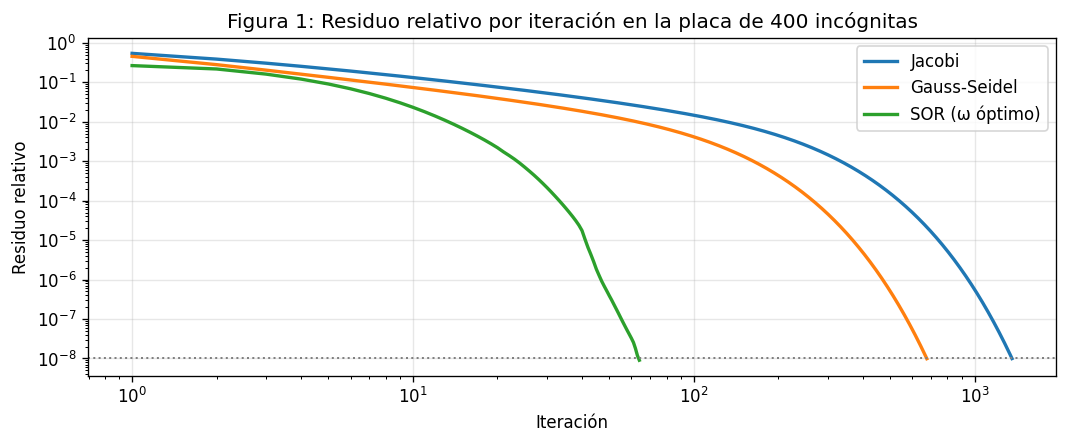

In [4]:
print("=== EXPERIMENTO 1: CONDUCCIÓN DE CALOR EN PLACA 2D (LAPLACE) ===\n")
print(f"{'N':<6} | {'Gauss (ms)':<11} | {'Jacobi (it / ms)':<18} | {'G-Seidel (it / ms)':<20} | {'SOR (it / ms)':<16} | {'omega':<6} | {'Err Max'}")
print("-" * 100)

residuos_400 = {}

for n in [10, 20, 30]:
    N = n * n
    A, b = construir_sistema_laplace(n)
    omega_opt = 2.0 / (1.0 + np.sin(np.pi / (n + 1)))

    # 1. Gauss con pivoteo parcial
    t0 = time.perf_counter()
    x_gauss = gauss_pivoteo_parcial(A, b)
    t_gauss = (time.perf_counter() - t0) * 1000

    # 2. Jacobi
    t0 = time.perf_counter()
    x_jac, it_jac, res_jac = jacobi_laplace(A, b)
    t_jac = (time.perf_counter() - t0) * 1000

    # 3. Gauss-Seidel (SOR con omega = 1.0)
    t0 = time.perf_counter()
    x_gs, it_gs, res_gs = sor_laplace(A, b, omega=1.0)
    t_gs = (time.perf_counter() - t0) * 1000

    # 4. SOR con omega óptimo
    t0 = time.perf_counter()
    x_sor, it_sor, res_sor = sor_laplace(A, b, omega=omega_opt)
    t_sor = (time.perf_counter() - t0) * 1000

    err_max = max(
        np.max(np.abs(x_gauss - x_jac)),
        np.max(np.abs(x_gauss - x_gs)),
        np.max(np.abs(x_gauss - x_sor))
    )

    if N == 400:
        residuos_400 = {'Jacobi': res_jac, 'Gauss-Seidel': res_gs, 'SOR (ω óptimo)': res_sor}

    print(f"{N:<6} | {t_gauss:<11.1f} | {f'{it_jac} / {t_jac:.1f}':<18} | {f'{it_gs} / {t_gs:.1f}':<20} | {f'{it_sor} / {t_sor:.1f}':<16} | {omega_opt:<6.3f} | {err_max:.1e}")

# Generar Figura 1: Residuo relativo en N = 400
plt.figure(figsize=(9, 3.8))
for nombre, hist in residuos_400.items():
    plt.loglog(range(1, len(hist) + 1), hist, linewidth=2, label=nombre)

plt.axhline(1e-8, color='gray', linestyle=':', linewidth=1.2)
plt.xlabel('Iteración')
plt.ylabel('Residuo relativo')
plt.title('Figura 1: Residuo relativo por iteración en la placa de 400 incógnitas')
plt.legend()
plt.grid(True, which="major", alpha=0.3)
plt.tight_layout()
plt.show()

=== EXPERIMENTO 2: SISTEMAS TRIDIAGONALES (POISSON 1D) ===

N      | Gauss (ms)   | Thomas (ms)   | Razón Gauss/Thomas   | Diferencia máxima
--------------------------------------------------------------------------------
200    | 11.6         | 0.42          | 28                   | 2.7e-12
400    | 71.6         | 0.85          | 84                   | 1.1e-11
800    | 572.4        | 1.63          | 352                  | 1.0e-10
1200   | 2359.4       | 2.44          | 966                  | 2.3e-10


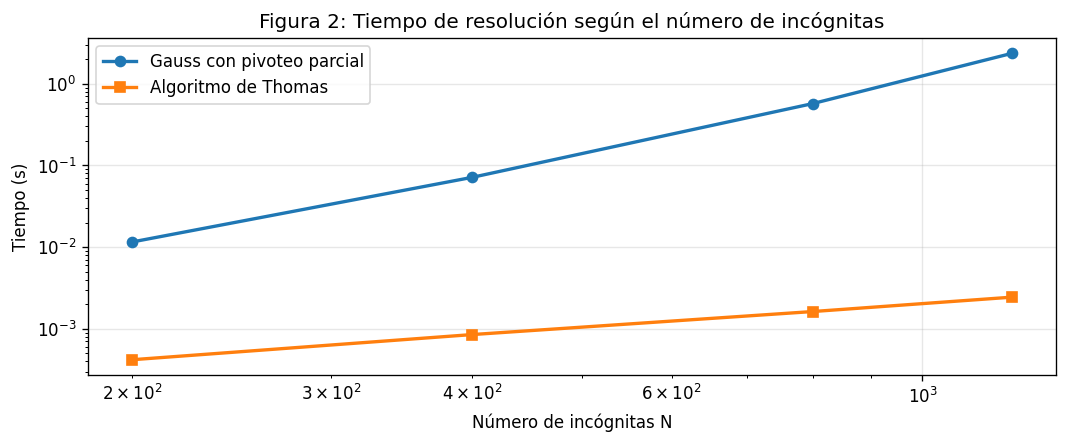

In [5]:
print("=== EXPERIMENTO 2: SISTEMAS TRIDIAGONALES (POISSON 1D) ===\n")
print(f"{'N':<6} | {'Gauss (ms)':<12} | {'Thomas (ms)':<13} | {'Razón Gauss/Thomas':<20} | {'Diferencia máxima'}")
print("-" * 80)

tamanos_N = [200, 400, 800, 1200]
tiempos_gauss = []
tiempos_thomas = []

for N in tamanos_N:
    a, b, c, d, A_densa = construir_sistema_tridiagonal(N)

    # Gauss con pivoteo parcial
    t0 = time.perf_counter()
    x_g = gauss_pivoteo_parcial(A_densa, d)
    t_g = (time.perf_counter() - t0) * 1000

    # Algoritmo de Thomas
    t0 = time.perf_counter()
    x_t = algoritmo_thomas(a, b, c, d)
    t_t = (time.perf_counter() - t0) * 1000

    tiempos_gauss.append(t_g / 1000.0)   # En segundos para Figura 2
    tiempos_thomas.append(t_t / 1000.0) # En segundos para Figura 2

    razon = t_g / t_t
    diff_max = np.max(np.abs(x_g - x_t))

    print(f"{N:<6} | {t_g:<12.1f} | {t_t:<13.2f} | {razon:<20.0f} | {diff_max:.1e}")

# Generar Figura 2: Tiempo de resolución vs N
plt.figure(figsize=(9, 3.8))
plt.loglog(tamanos_N, tiempos_gauss, marker='o', linewidth=2, label='Gauss con pivoteo parcial')
plt.loglog(tamanos_N, tiempos_thomas, marker='s', linewidth=2, label='Algoritmo de Thomas')

plt.xlabel('Número de incógnitas N')
plt.ylabel('Tiempo (s)')
plt.title('Figura 2: Tiempo de resolución según el número de incógnitas')
plt.legend()
plt.grid(True, which="major", alpha=0.3)
plt.tight_layout()
plt.show()